<a href="https://colab.research.google.com/github/psh135230-design/BioAI_KU_2026/blob/main/%EB%B0%94%EC%9D%B4%EC%98%A4%EC%9D%B8%EA%B3%B5%EC%A7%80%EB%8A%A5_w3_QC_%EC%88%98%EC%A0%95%EB%B3%B8(%EB%85%BC%EB%AC%B8_R_code_%EC%B0%B8%EA%B3%A0).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
from google.colab import drive

drive.mount('/content/drive')

target_path = '/content/drive/MyDrive/바이오 인공지능 '

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# GSE326061 (lib1)
!wget -q -O GSE326061_RAW.tar "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE326nnn/GSE326061/suppl/GSE326061_RAW.tar"
!tar -xvf GSE326061_RAW.tar

# GSE325953 (lib2)
!wget -q -O GSE325953_RAW.tar "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE325nnn/GSE325953/suppl/GSE325953_RAW.tar"
!tar -xvf GSE325953_RAW.tar

GSM9621184_Cell_Metadata.csv.gz
GSM9621184_lib1_barcodes.tsv.gz
GSM9621184_lib1_features.tsv.gz
GSM9621184_lib1_matrix.mtx.gz
GSM9617712_Cell_Metadata.csv.gz
GSM9617712_lib2_barcodes.tsv.gz
GSM9617712_lib2_features.tsv.gz
GSM9617712_lib2_matrix.mtx.gz


In [3]:
import os
print([f for f in os.listdir('.') if f.startswith('GSM9621184') or f.startswith('GSM9617712')])

['GSM9617712_lib2_features.tsv.gz', 'GSM9621184_lib1_barcodes.tsv.gz', 'GSM9621184_lib1_matrix.mtx.gz', 'GSM9617712_lib2_barcodes.tsv.gz', 'GSM9621184_Cell_Metadata.csv.gz', 'GSM9617712_Cell_Metadata.csv.gz', 'GSM9617712_lib2_matrix.mtx.gz', 'GSM9621184_lib1_features.tsv.gz']


In [4]:
import pandas as pd
import scanpy as sc

# 1. 메타데이터 CSV 원본 구조 확인 (index_col=0 가정이 맞는지)
meta_raw = pd.read_csv("GSM9621184_Cell_Metadata.csv.gz")
print("메타데이터 컬럼:", meta_raw.columns.tolist())
print(meta_raw.head())

# 2. index_col=0으로 읽었을 때 실제 인덱스 값
meta = pd.read_csv("GSM9621184_Cell_Metadata.csv.gz", index_col=0)
print("\n메타데이터 인덱스 예시 5개:", meta.index[:5].tolist())

# 3. mtx에서 나온 실제 바코드
adata_test = sc.read_10x_mtx(".", prefix="GSM9621184_lib1_", var_names="gene_symbols")
print("\nmtx 바코드 예시 5개:", adata_test.obs_names[:5].tolist())

메타데이터 컬럼: ['cell_barcode', 'treatment', 'cell_type', 'cluster']
       cell_barcode                 treatment    cell_type  cluster
0  AAACCCATCATTGGTG  N297A (Agonist, Fc-null)    Monocytes        0
1  AAACCCATCGTCGATA  N297A (Agonist, Fc-null)  Macrophages        5
2  AAACGAAAGTTGTAAG  N297A (Agonist, Fc-null)          CD8       23
3  AAACGCTAGAGCTGCA  N297A (Agonist, Fc-null)    Monocytes       18
4  AAACGCTAGTTGTCAC  N297A (Agonist, Fc-null)          CD8       38

메타데이터 인덱스 예시 5개: ['AAACCCATCATTGGTG', 'AAACCCATCGTCGATA', 'AAACGAAAGTTGTAAG', 'AAACGCTAGAGCTGCA', 'AAACGCTAGTTGTCAC']

mtx 바코드 예시 5개: ['AAACCCAAGAAACCAT-1', 'AAACCCAAGAAACTAC-1', 'AAACCCAAGAAACTCA-1', 'AAACCCAAGAAACTGT-1', 'AAACCCAAGAAAGCGA-1']


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Installed: scanpy==1.11.5, anndata==0.12.19
scanpy 1.11.5
anndata 0.12.19
[GSE326061.sparse.h5ad] 변환 시작... (prefix='GSM9621184_lib1_')
[GSE326061.sparse.h5ad] 바코드 매칭: 18,302 / raw 2,965,363 (메타데이터 18,302개)
GSE326061.sparse.h5ad 생성 완료!

[GSE325953.sparse.h5ad] 변환 시작... (prefix='GSM9617712_lib2_')
[GSE325953.sparse.h5ad] 바코드 매칭: 18,377 / raw 2,979,617 (메타데이터 18,377개)
GSE325953.sparse.h5ad 생성 완료!



/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:222: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  adata.var["mt"] = adata.var_names.str.upper().str.contains(r"(^|[_.])MT-", regex=True)


[GSE326061] 미토콘드리아 유전자 26개 검출
[GSE326061] QC 이전: 18,302 cells


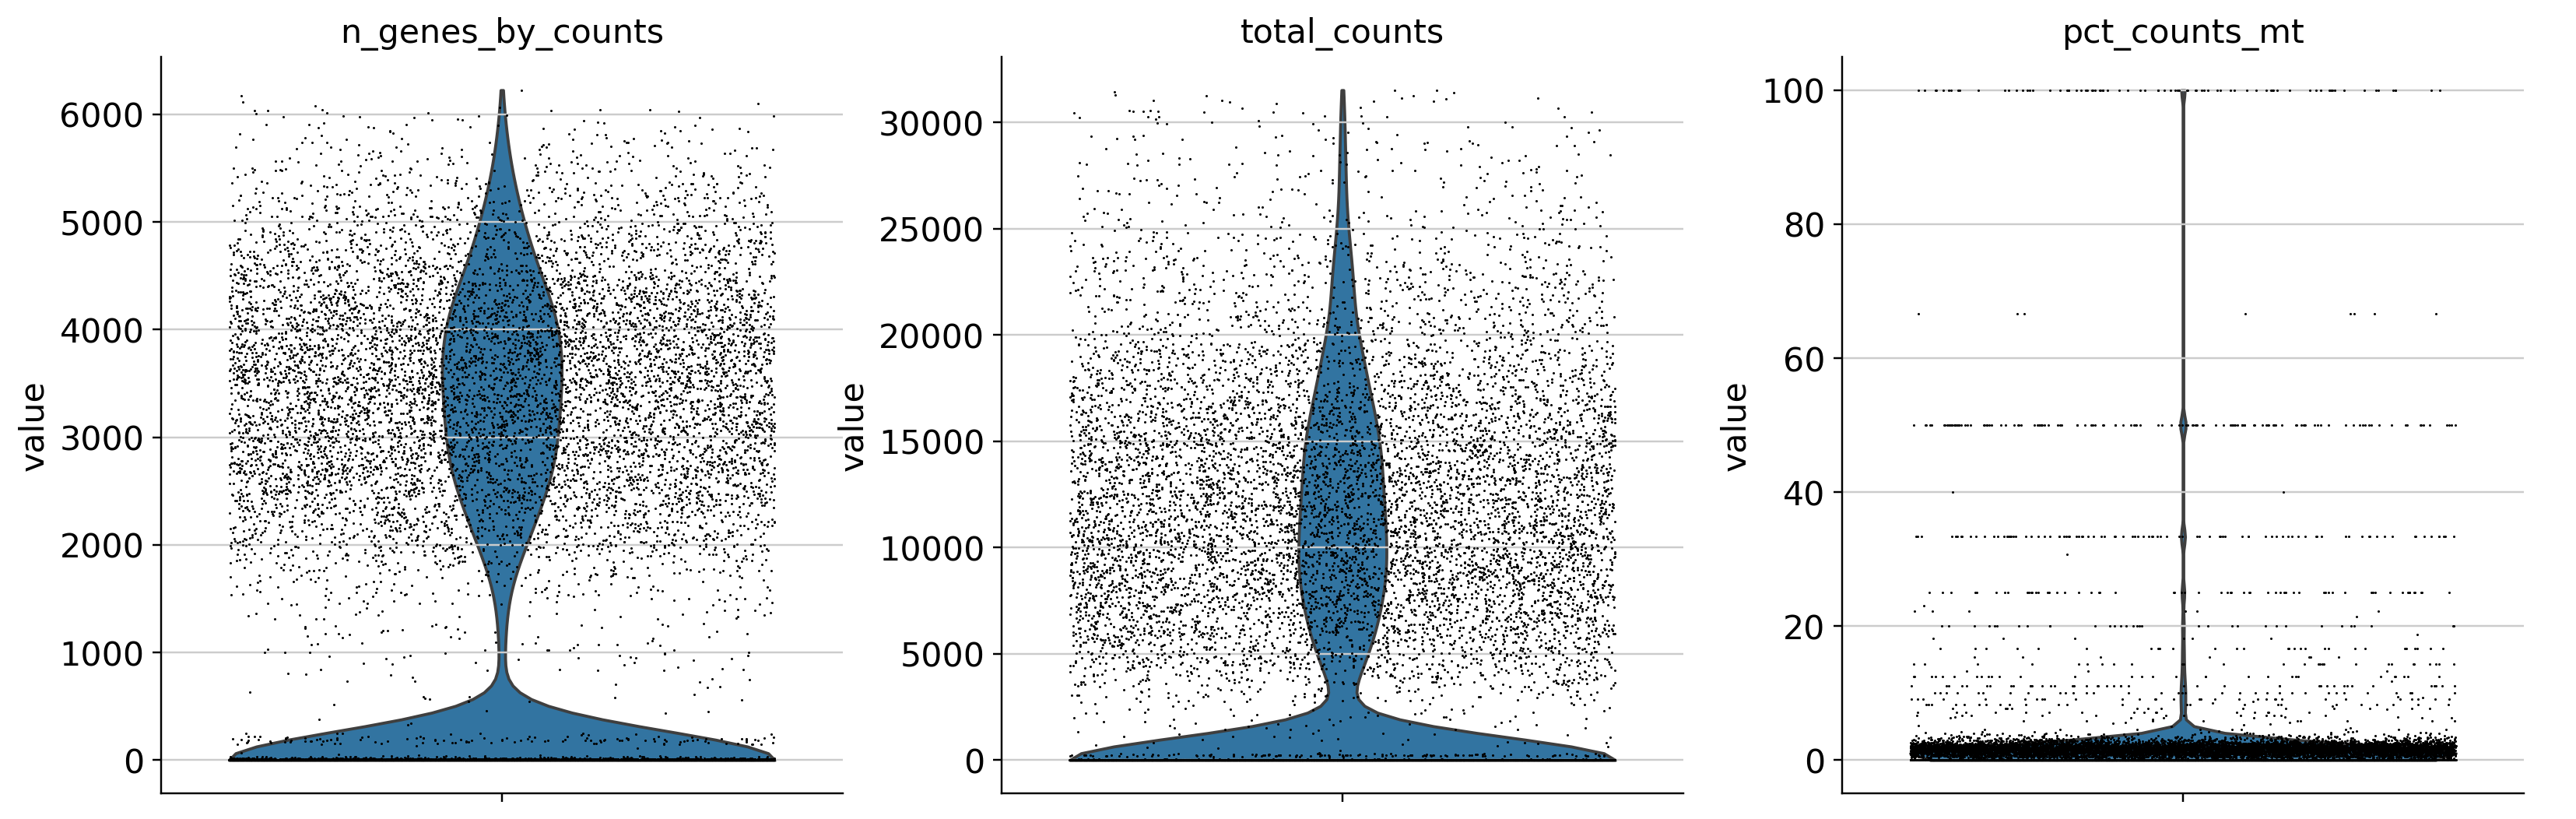

<Figure size 440x440 with 0 Axes>

/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 52983 (\N{HANGUL SYLLABLE KEOS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 54532 (\N{HANGUL SYLLABLE PEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 48744 (\N{HANGUL SYLLABLE BBAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 51216 (\N{HANGUL SYLLABLE JEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.

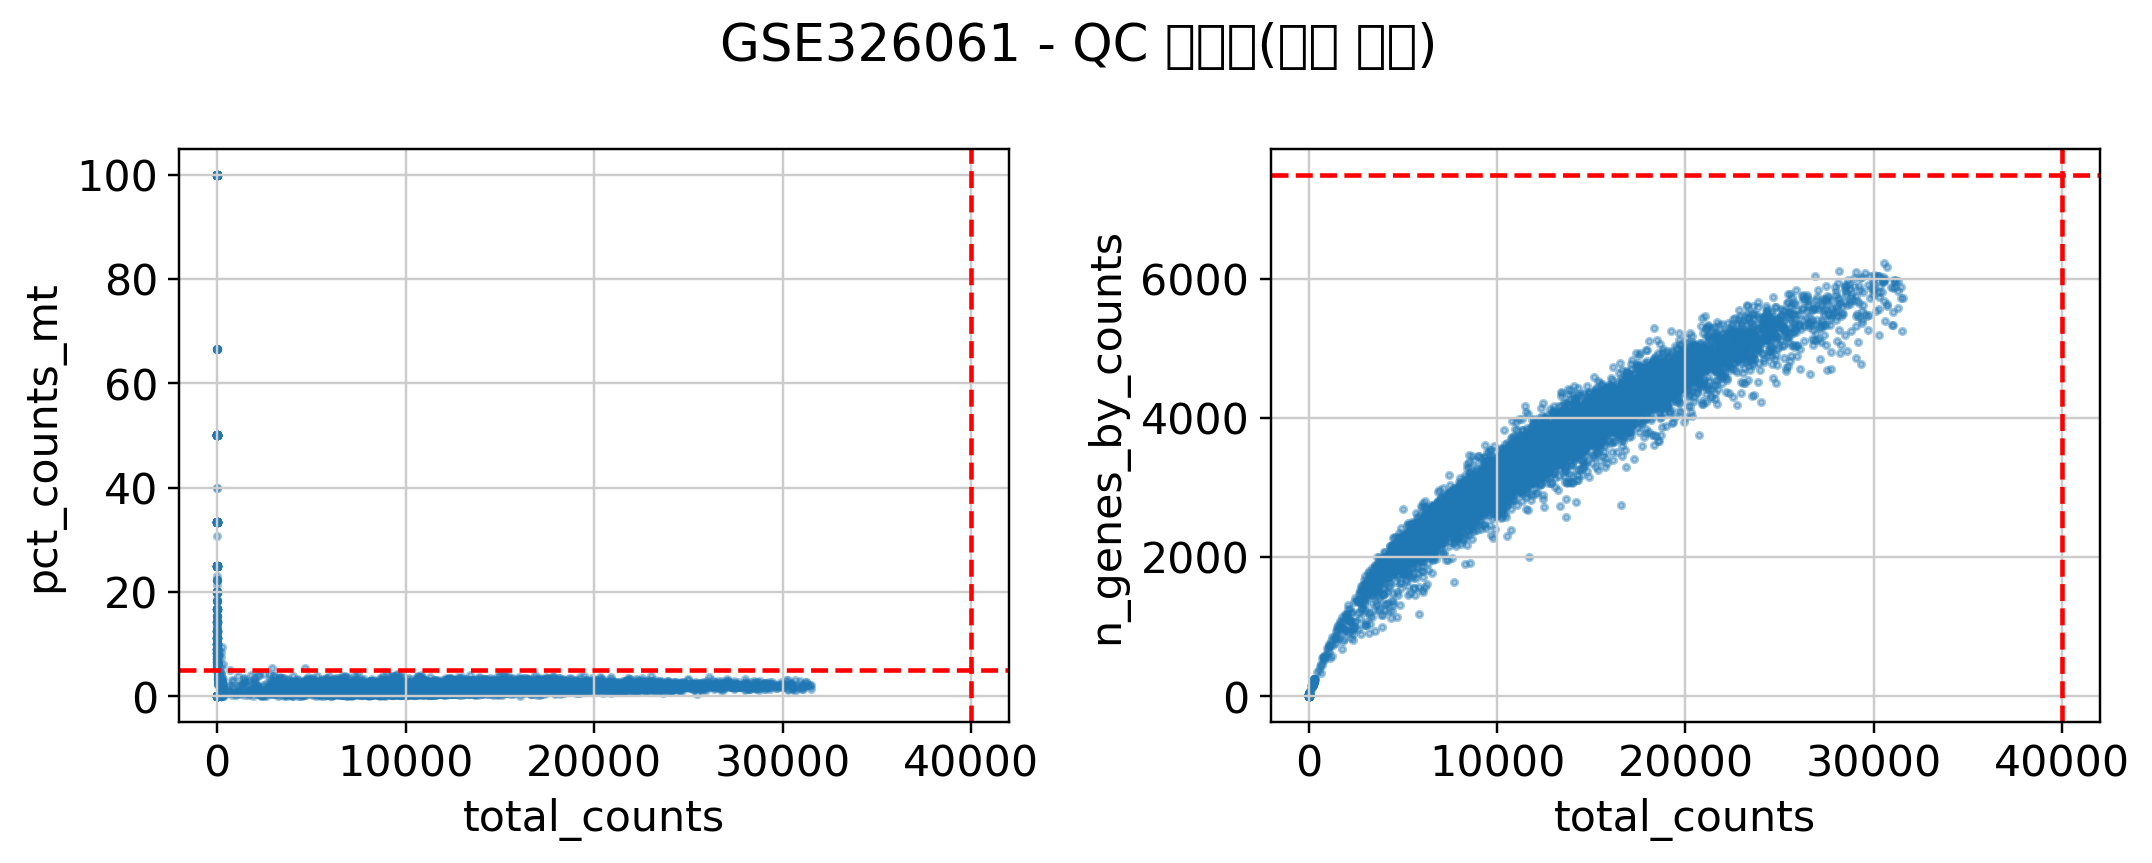

[GSE326061] QC 이후: 16,405 cells (제거: 1,897개, 10.4%)


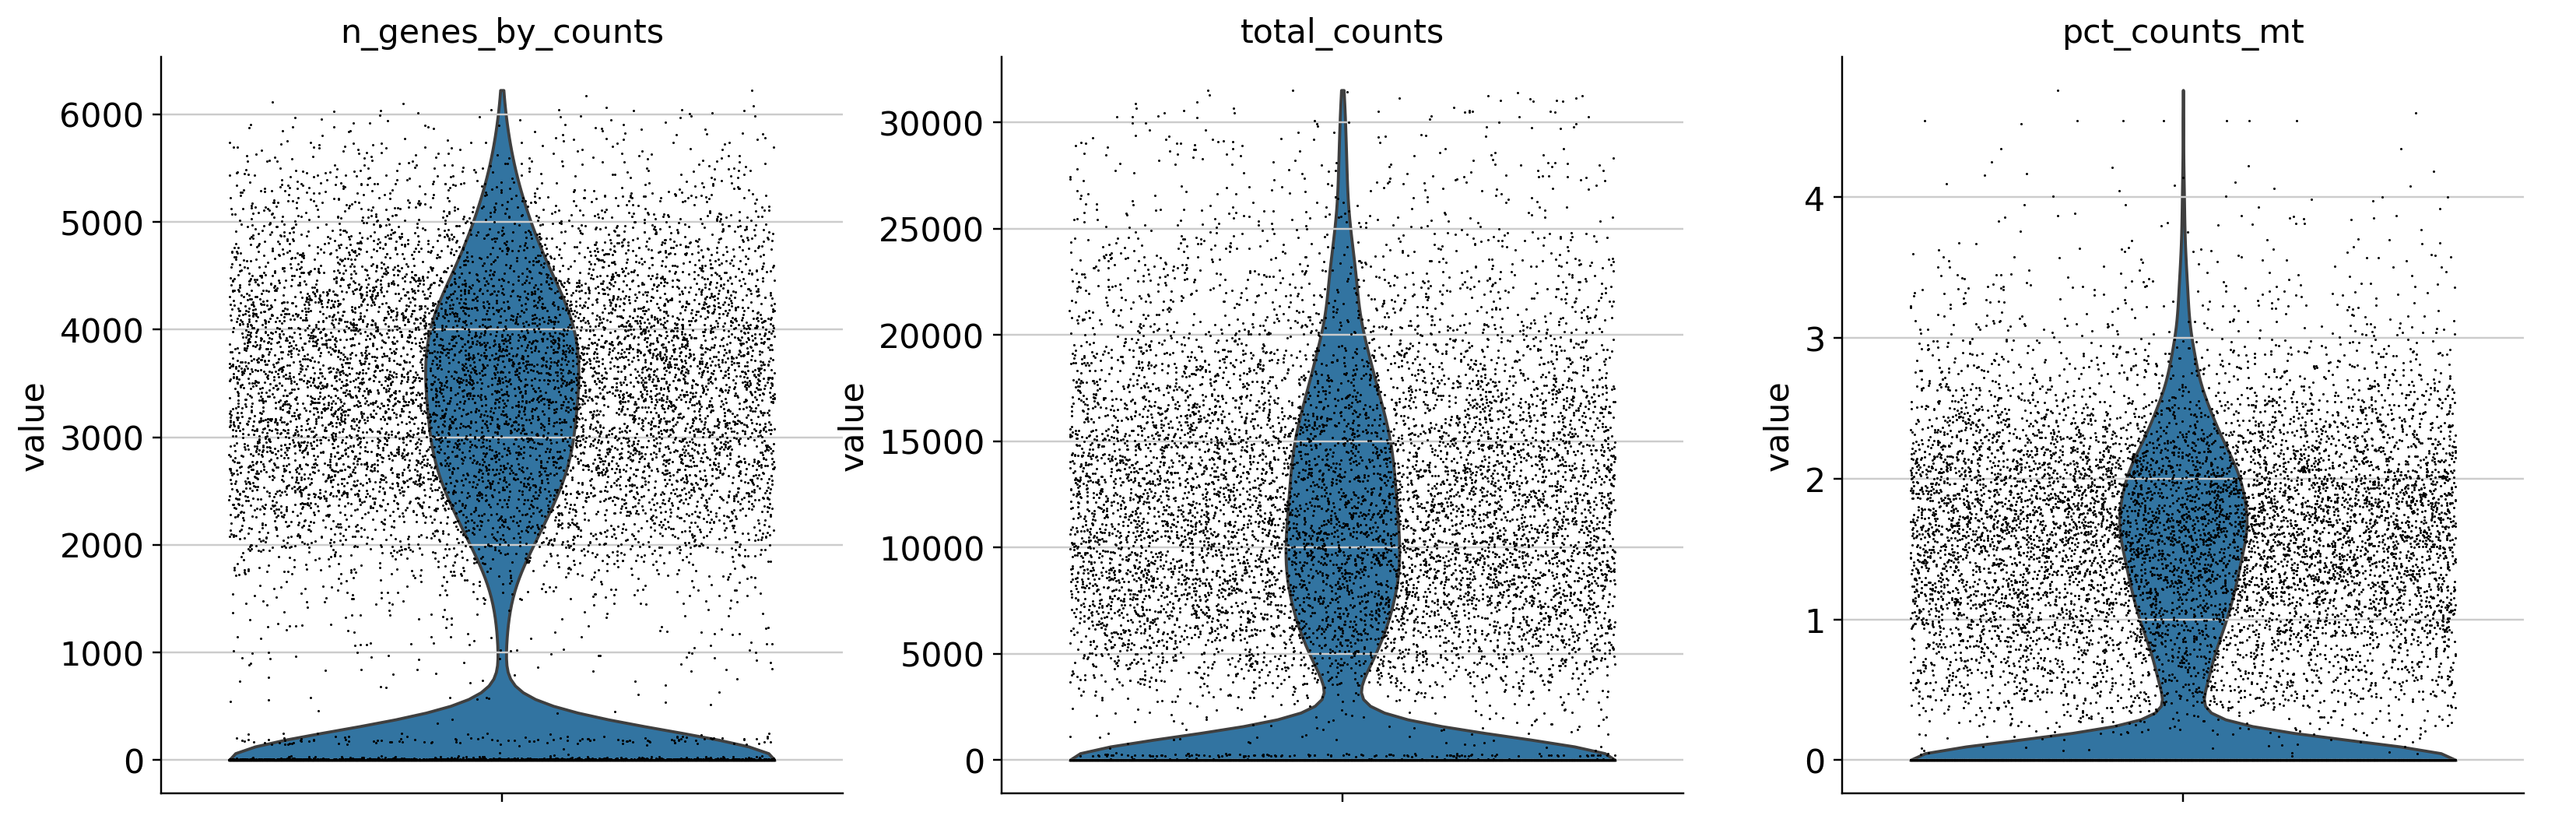

<Figure size 440x440 with 0 Axes>

/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:222: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  adata.var["mt"] = adata.var_names.str.upper().str.contains(r"(^|[_.])MT-", regex=True)


[GSE325953] 미토콘드리아 유전자 26개 검출
[GSE325953] QC 이전: 18,377 cells


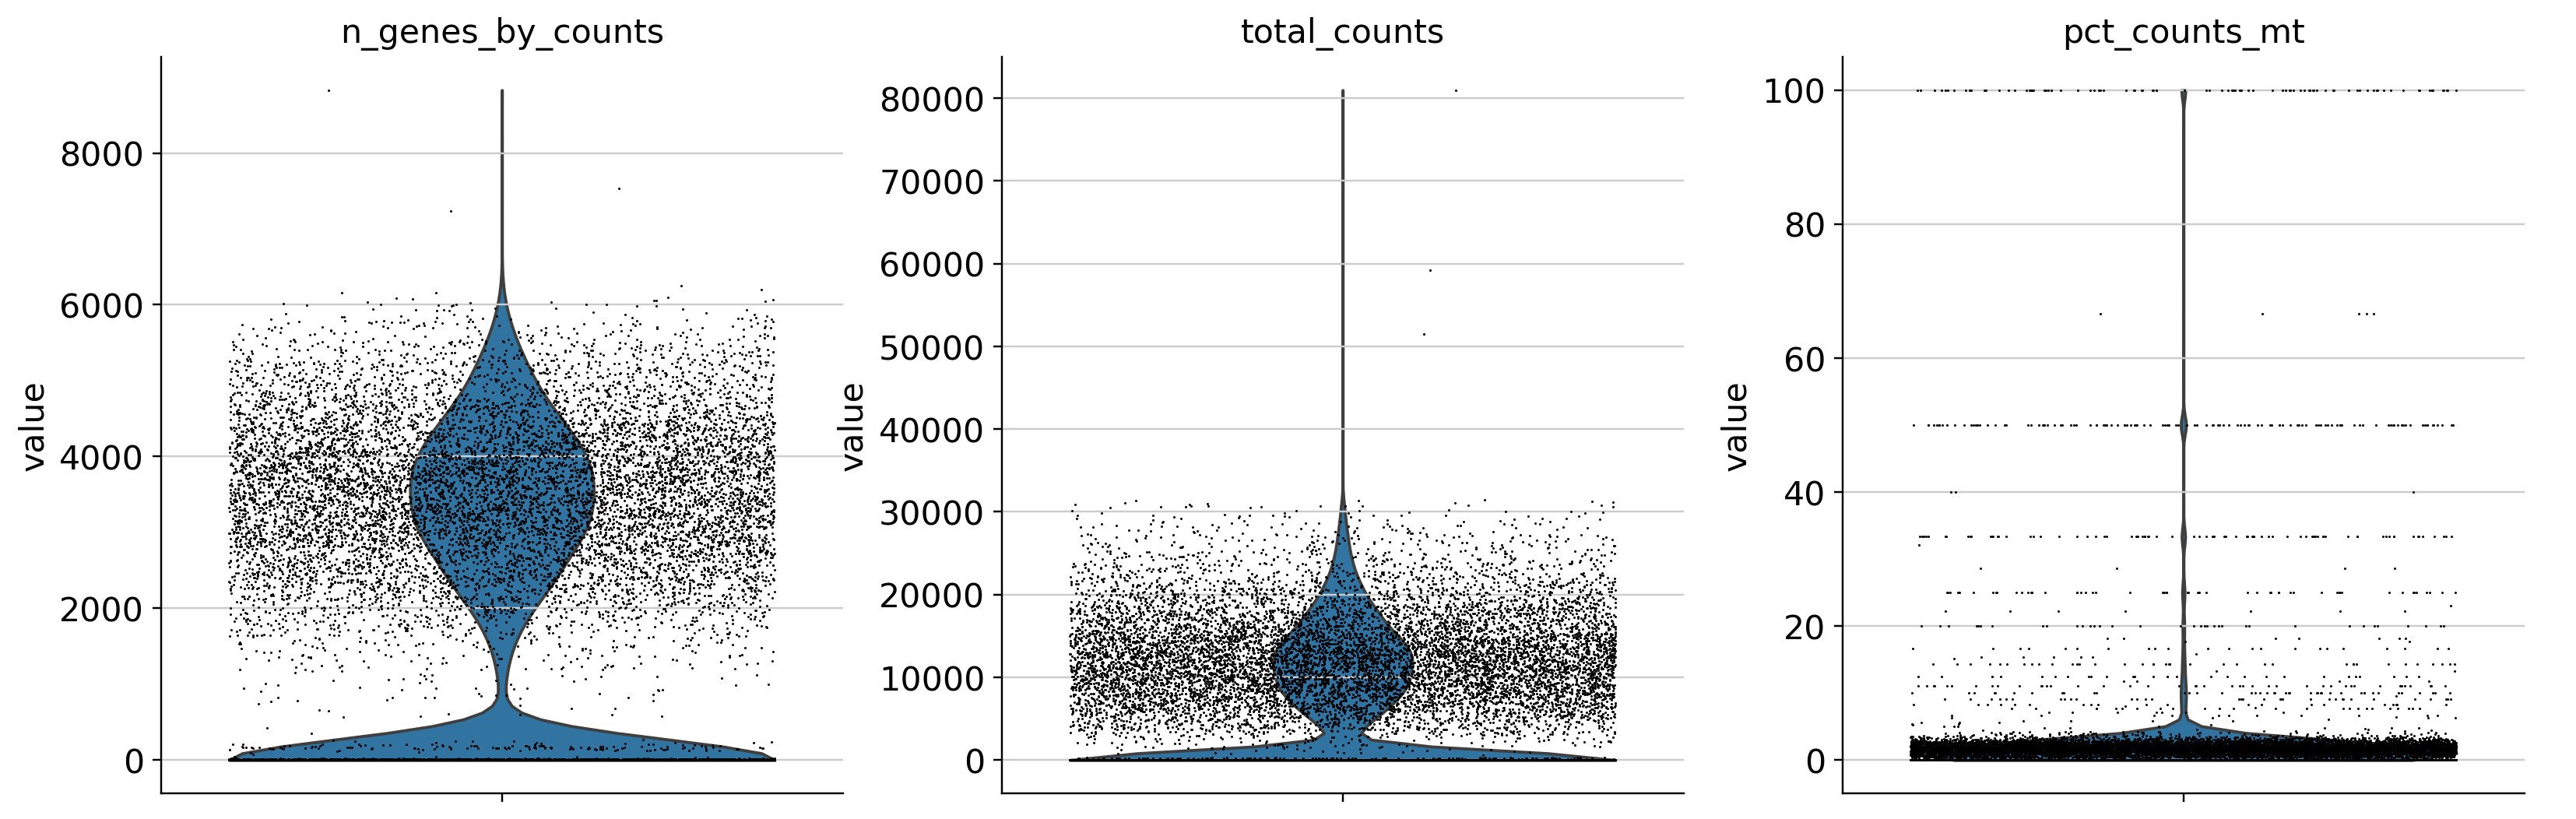

<Figure size 440x440 with 0 Axes>

/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 52983 (\N{HANGUL SYLLABLE KEOS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 54532 (\N{HANGUL SYLLABLE PEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 48744 (\N{HANGUL SYLLABLE BBAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.py:261: UserWarning: Glyph 51216 (\N{HANGUL SYLLABLE JEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/drive/MyDrive/바이오 인공지능 /scRNA_QC_FF.

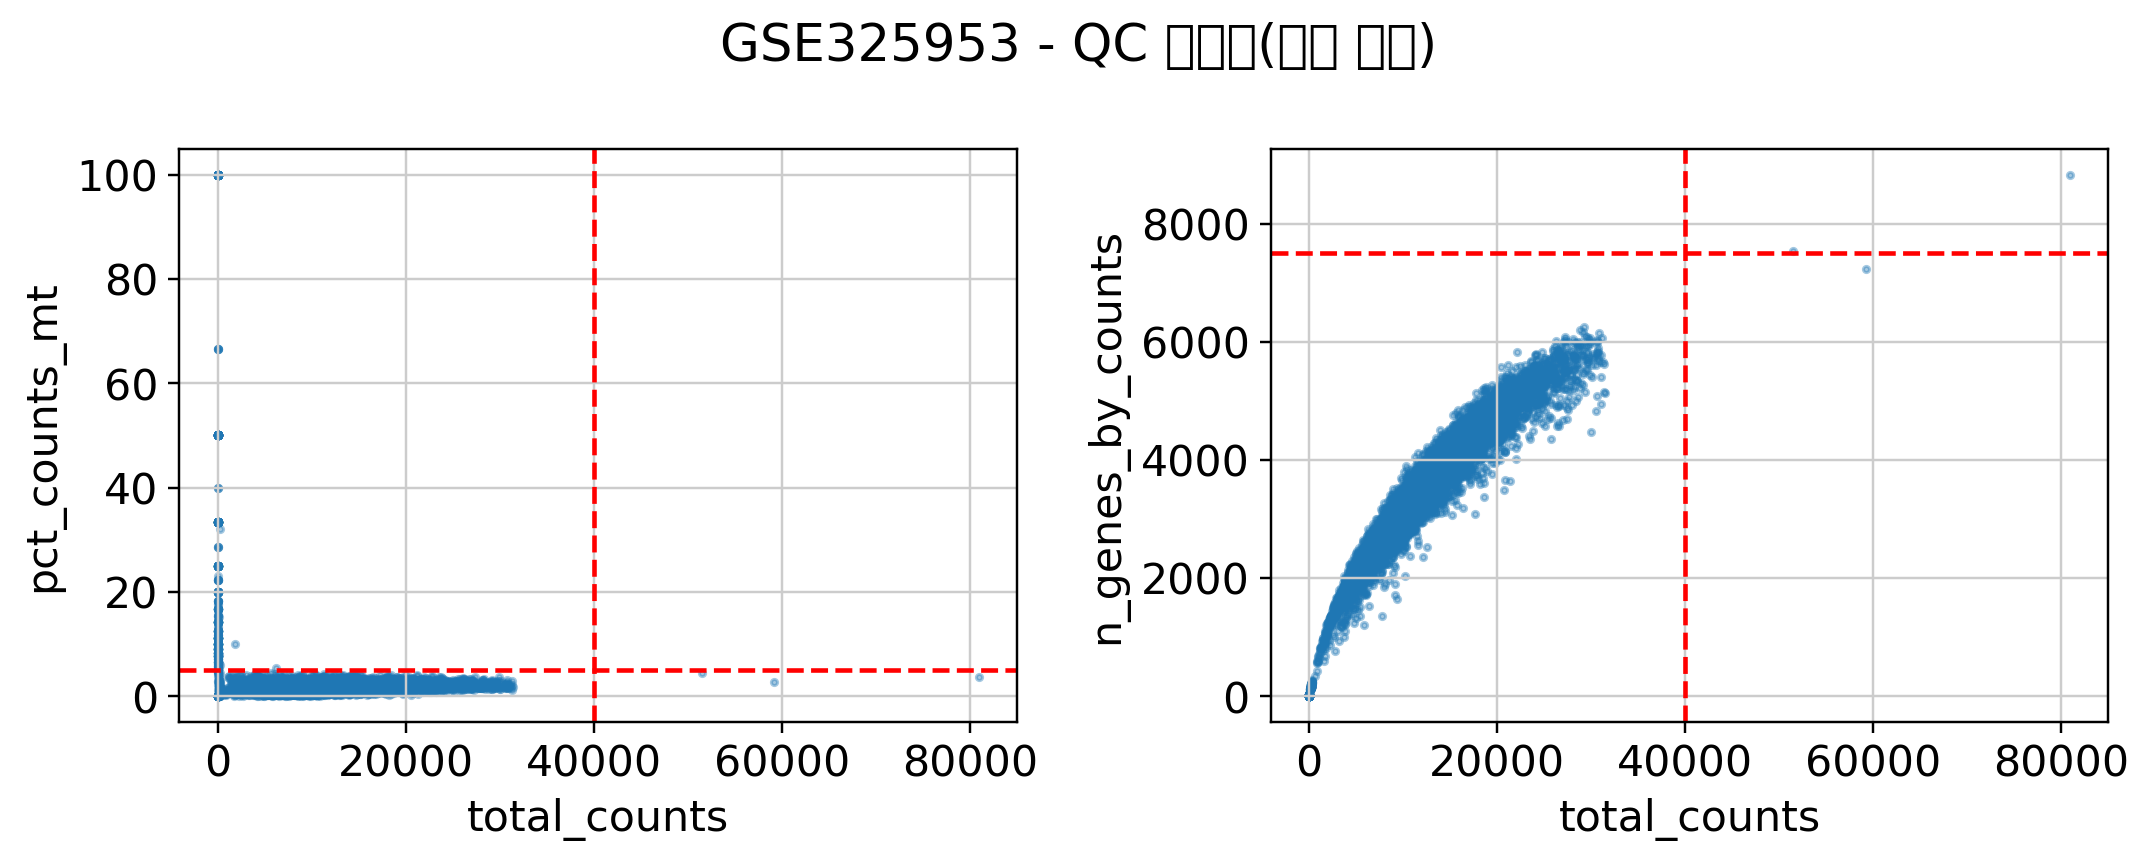

[GSE325953] QC 이후: 16,348 cells (제거: 2,029개, 11.0%)


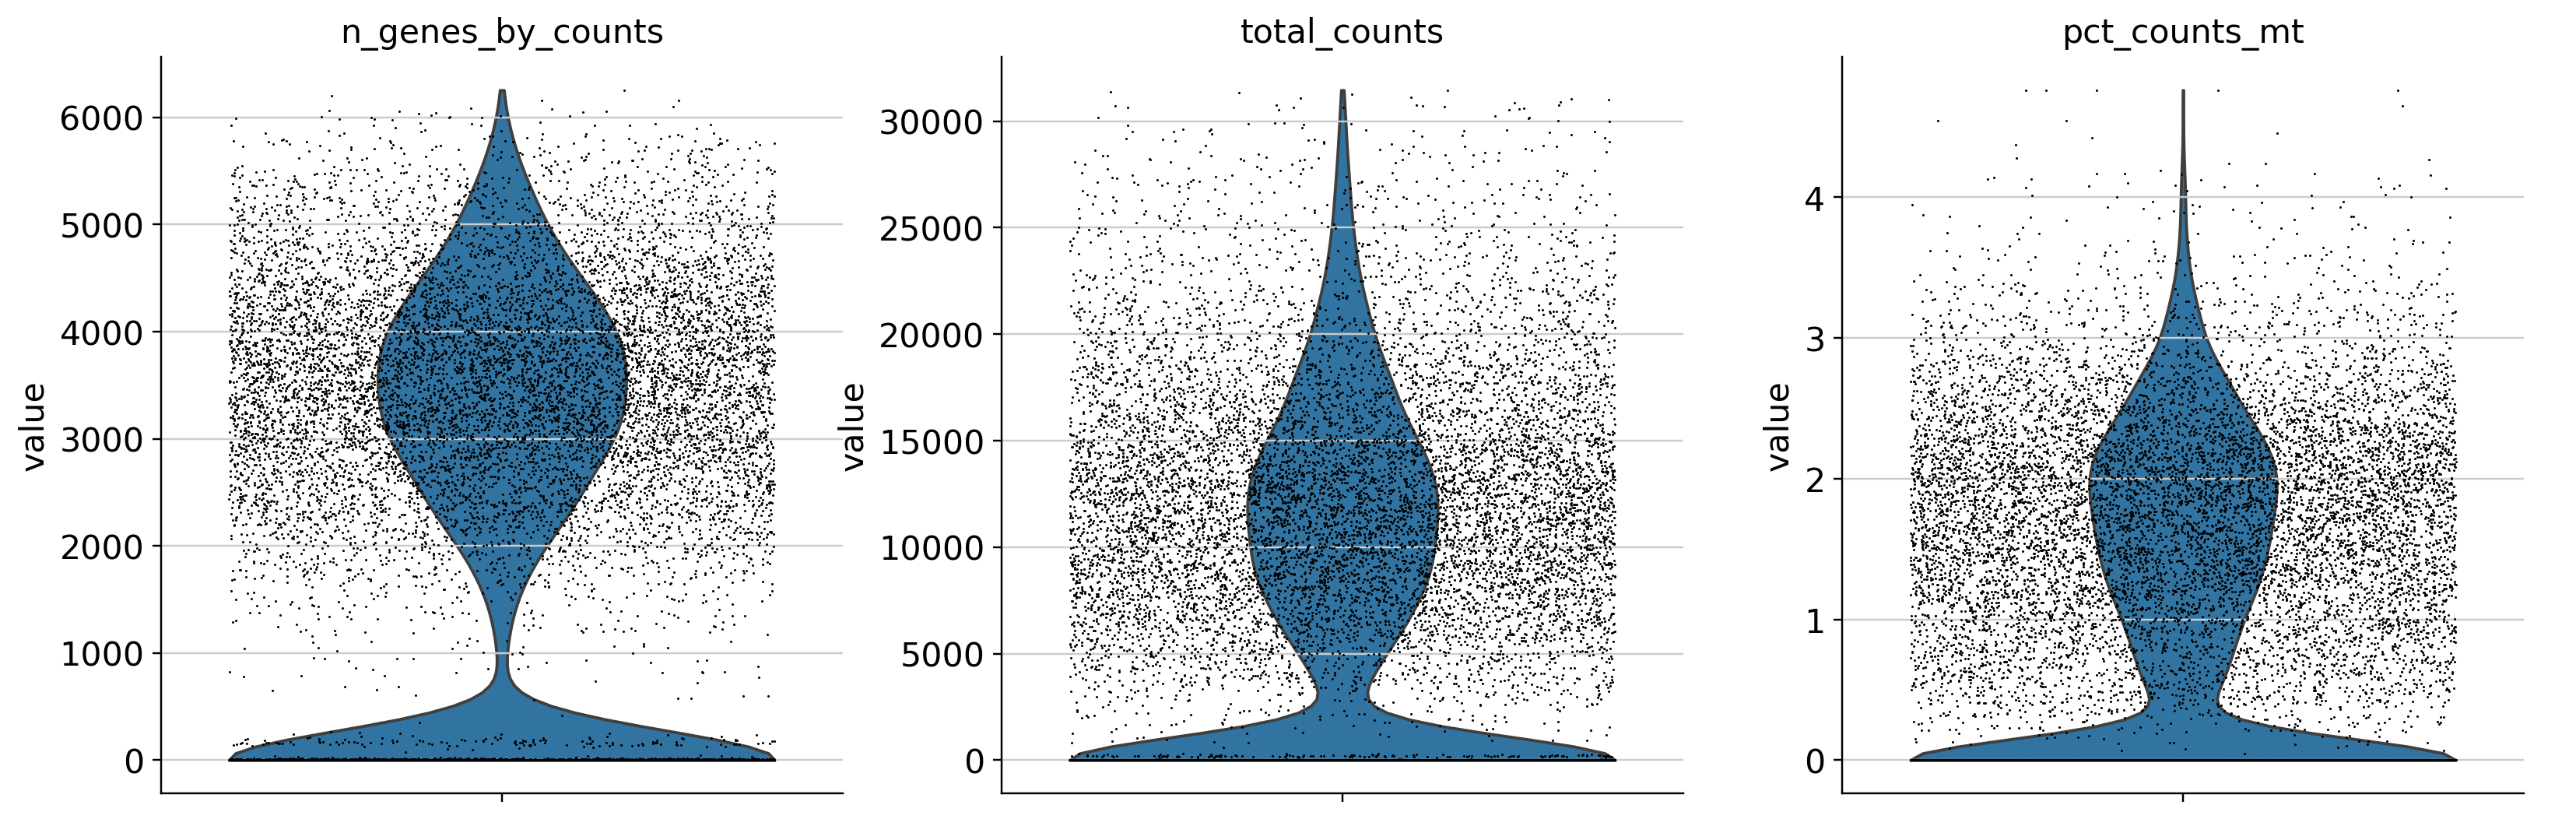

<Figure size 440x440 with 0 Axes>


=== QC 요약 ===
     dataset  cells_before  cells_after  cells_removed
0  GSE326061         18302        16405           1897
1  GSE325953         18377        16348           2029


<Figure size 440x440 with 0 Axes>

In [5]:
from google.colab import drive

drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/바이오 인공지능 ')

%run scRNA_QC_FF.py
# QC 후 세포 수가 완전히 일치하지는 않으나 논문에서 해당 h5ad 파일을 비공개함
# 로직은 논문이 제공한 그대로 따름

In [6]:
# Install the same Scanpy and AnnData versions used in the course.
import subprocess
import sys

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "scanpy==1.11.5", "anndata==0.12.19",
])
print("Installation complete. Continue with the imports below.")

Installation complete. Continue with the imports below.


In [7]:
from pathlib import Path
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse
from IPython.display import display

sc.settings.verbosity = 0
sc.settings.datasetdir = Path("data")
sc.settings.set_figure_params(dpi=100, facecolor="white", frameon=True)
print("Scanpy:", version("scanpy"), "| AnnData:", version("anndata"))

Scanpy: 1.11.5 | AnnData: 0.12.19


In [9]:
import matplotlib.pyplot as plt
import gc # gc 모듈을 명시적으로 임포트

# 1. 두 파일 각각 읽기
adata1 = adata_by_output['GSE326061.sparse.h5ad']
adata2 = adata_by_output['GSE325953.sparse.h5ad']

adata = sc.concat(
    {"sample1": adata1, "sample2": adata2}, label="sample", join="outer"
)

# 3. 불필요해진 이전 변수 삭제하여 RAM 확보
del adata1, adata2
gc.collect()

# 4. 데이터 크기를 줄이기 위한 기본 필터링 (최소 3개 세포 이상 발현 유전자만 유지)
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)

# 4. QC 진행
adata.var_names_make_unique()
adata.var["mt"] = adata.var_names.str.startswith("MT-")  # 마우스 데이터면 "mt-" 또는 "Mt-"로 변경
sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True,
)

display(adata.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].describe().round(1))

# 5. Normalize and log-transform data before HVG for 'seurat' flavor
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# 6. HVG
N_HVG = 2000
sc.pp.highly_variable_genes(
    adata, flavor="seurat", n_top_genes=N_HVG, subset=False
)

# 7. Scaling (zero_center=False로 희소 행렬 유지하여 RAM 초과 방지)
sc.pp.scale(adata, max_value=10, zero_center=False)

# 8. PCA 실행
sc.pp.pca(adata, n_comps=30, svd_solver="arpack", random_state=0)


/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


,total_counts,n_genes_by_counts,pct_counts_mt
count,19297.0,19297.0,19297.0
mean,12617.8,3492.0,0.0
std,5687.3,994.8,0.0
min,217.0,200.0,0.0
25%,8449.0,2803.0,0.0
50%,12043.0,3501.0,0.0
75%,16081.0,4180.0,0.0
max,80951.0,8812.0,0.0


In [13]:
result_df = pd.DataFrame()

for sample_id in adata.obs["sample"].unique():
    # 1. 해당 샘플 데이터만 추출
    sub_adata = adata[adata.obs["sample"] == sample_id].copy()

    # 2. 해당 샘플의 평균 표현량 계산
    mean_log_expr = pd.Series(
        np.asarray(sub_adata.X.mean(axis=0)).ravel(), index=sub_adata.var_names
    )
    top_expr = mean_log_expr.sort_values(ascending=False).head(10)

    # 3. 해당 샘플의 HVG 추출
    sub_hvg = sub_adata.var[sub_adata.var["highly_variable"]].sort_values(
        "dispersions_norm", ascending=False
    )

    # 4. 각 샘플의 결과를 표 컬럼으로 추가
    result_df[f"[{sample_id}] Highest Mean"] = top_expr.index
    result_df[f"[{sample_id}] Highest HVG"] = sub_hvg.head(10).index

    # 5. 겹치는 개수 출력
    shared = len(set(top_expr.index) & set(sub_hvg.head(10).index))
    print(f"[{sample_id}] Shared genes between Mean & HVG: {shared}")

# 두 샘플의 비교 표 한 번에 출력
display(result_df)

[sample1] Shared genes between Mean & HVG: 0
[sample2] Shared genes between Mean & HVG: 0


,[sample1] Highest Mean,[sample1] Highest HVG,[sample2] Highest Mean,[sample2] Highest HVG
0,GRCm39_Tmsb4x,GRCm39_Hbb-bs,GRCm39_Tmsb4x,GRCm39_Hbb-bs
1,GRCm39_Tpt1,GRCm39_Slpi,GRCm39_Tpt1,GRCm39_Slpi
2,GRCm39_Fau,GRCm39_Hba-a1,GRCm39_B2m,GRCm39_Hba-a1
3,GRCm39_B2m,GRCm39_S100a9,GRCm39_Fau,GRCm39_S100a9
4,GRCm39_Actb,GRCm39_Hba-a2,GRCm39_Actb,GRCm39_Hba-a2
5,GRCm39_Eef1a1,GRCm39_Hbb-bt,GRCm39_Rps29,GRCm39_Hbb-bt
6,GRCm39_Rpl41,GRCm39_S100a8,GRCm39_Rpl41,GRCm39_S100a8
7,GRCm39_Rps24,GRCm39_Ccl8,GRCm39_Eef1a1,GRCm39_Ccl8
8,GRCm39_Rpl35a,GRCm39_Gzmf,GRCm39_Rpl35a,GRCm39_Gzmf
9,GRCm39_Rpl19,GRCm39_Ccl24,GRCm39_Rps24,GRCm39_Ccl24


In [14]:
summary_list = []

for sample_id in adata.obs["sample"].unique():
    # 1. 해당 샘플의 HVG 데이터만 추출
    sub_adata = adata[adata.obs["sample"] == sample_id].copy()
    pca_data = sub_adata[:, sub_adata.var["highly_variable"]].copy()

    # 2. Sparse matrix 변환 및 Scale
    if sparse.issparse(pca_data.X):
        pca_data.X = pca_data.X.toarray()

    sc.pp.scale(pca_data, zero_center=True, max_value=10)

    # 3. PCA 실행
    sc.pp.pca(
        pca_data,
        n_comps=30,
        svd_solver="arpack",
        random_state=0,
        mask_var=None,
    )

    # 4. 각 샘플별 Shape 정보 정리
    df_sample = pd.DataFrame(
        {
            "Sample": sample_id,
            "Output": ["Scaled input", "Cell scores", "Gene loadings"],
            "Location": [
                "pca_data.X",
                "pca_data.obsm['X_pca']",
                "pca_data.varm['PCs']",
            ],
            "Shape": [
                str(pca_data.X.shape),
                str(pca_data.obsm["X_pca"].shape),
                str(pca_data.varm["PCs"].shape),
            ],
        }
    )
    summary_list.append(df_sample)

# 두 샘플의 요약 결과 합쳐서 출력
pca_summary_df = pd.concat(summary_list, ignore_index=True)
display(pca_summary_df)

,Sample,Output,Location,Shape
0,sample1,Scaled input,pca_data.X,"(8784, 2000)"
1,sample1,Cell scores,pca_data.obsm['X_pca'],"(8784, 30)"
2,sample1,Gene loadings,pca_data.varm['PCs'],"(2000, 30)"
3,sample2,Scaled input,pca_data.X,"(10513, 2000)"
4,sample2,Cell scores,pca_data.obsm['X_pca'],"(10513, 30)"
5,sample2,Gene loadings,pca_data.varm['PCs'],"(2000, 30)"


[sample1] PC1 + PC2 explain 10.4% of variation in the scaled HVG input.
[sample2] PC1 + PC2 explain 10.1% of variation in the scaled HVG input.


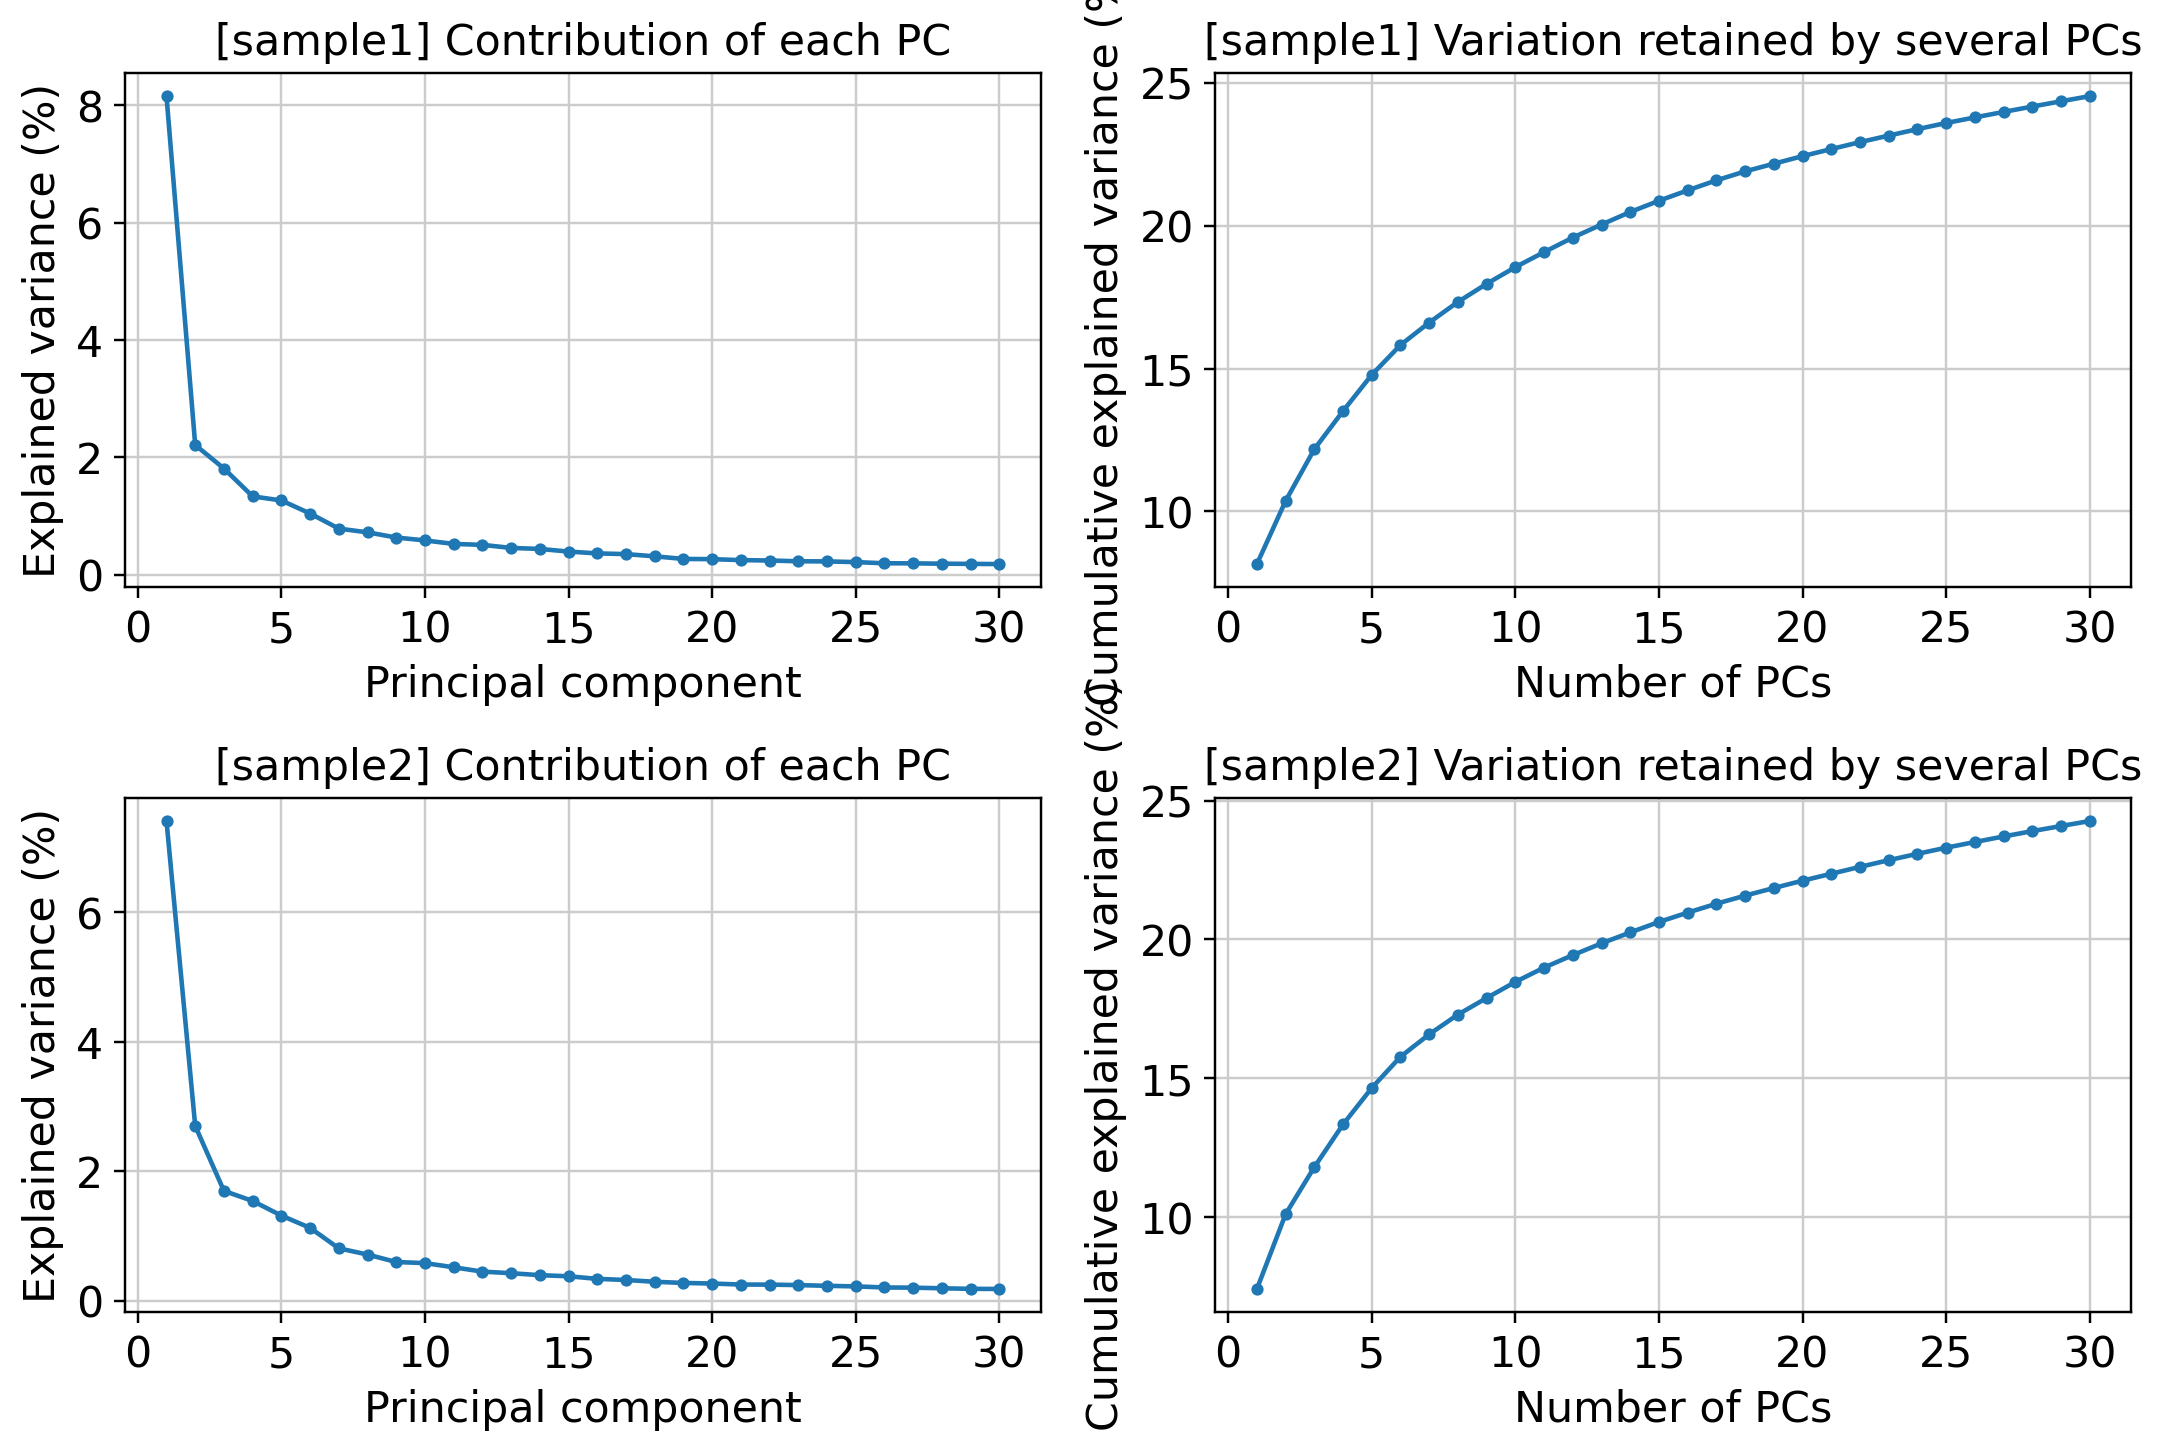

In [15]:
samples = adata.obs["sample"].unique()
fig, axes = plt.subplots(len(samples), 2, figsize=(10, 3.4 * len(samples)))

for idx, sample_id in enumerate(samples):
    # 1. 해당 샘플의 HVG 추출 및 PCA 계산
    sub_adata = adata[adata.obs["sample"] == sample_id].copy()
    pca_data = sub_adata[:, sub_adata.var["highly_variable"]].copy()

    if sparse.issparse(pca_data.X):
        pca_data.X = pca_data.X.toarray()

    sc.pp.scale(pca_data, zero_center=True, max_value=10)
    sc.pp.pca(pca_data, n_comps=30, svd_solver="arpack", random_state=0)

    # 2. 분산 비율 추출
    variance = pca_data.uns["pca"]["variance_ratio"]
    pcs = np.arange(1, len(variance) + 1)

    # 행 인덱스 처리 (샘플이 1개일 경우 대비)
    ax_row = axes[idx] if len(samples) > 1 else axes

    # 3. 그래프 작성
    ax_row[0].plot(pcs, 100 * variance, "o-", markersize=3)
    ax_row[0].set(
        xlabel="Principal component",
        ylabel="Explained variance (%)",
        title=f"[{sample_id}] Contribution of each PC",
    )

    ax_row[1].plot(pcs, 100 * np.cumsum(variance), "o-", markersize=3)
    ax_row[1].set(
        xlabel="Number of PCs",
        ylabel="Cumulative explained variance (%)",
        title=f"[{sample_id}] Variation retained by several PCs",
    )

    print(
        f"[{sample_id}] PC1 + PC2 explain {100 * variance[:2].sum():.1f}% of variation in the scaled HVG input."
    )

fig.tight_layout()
plt.show()

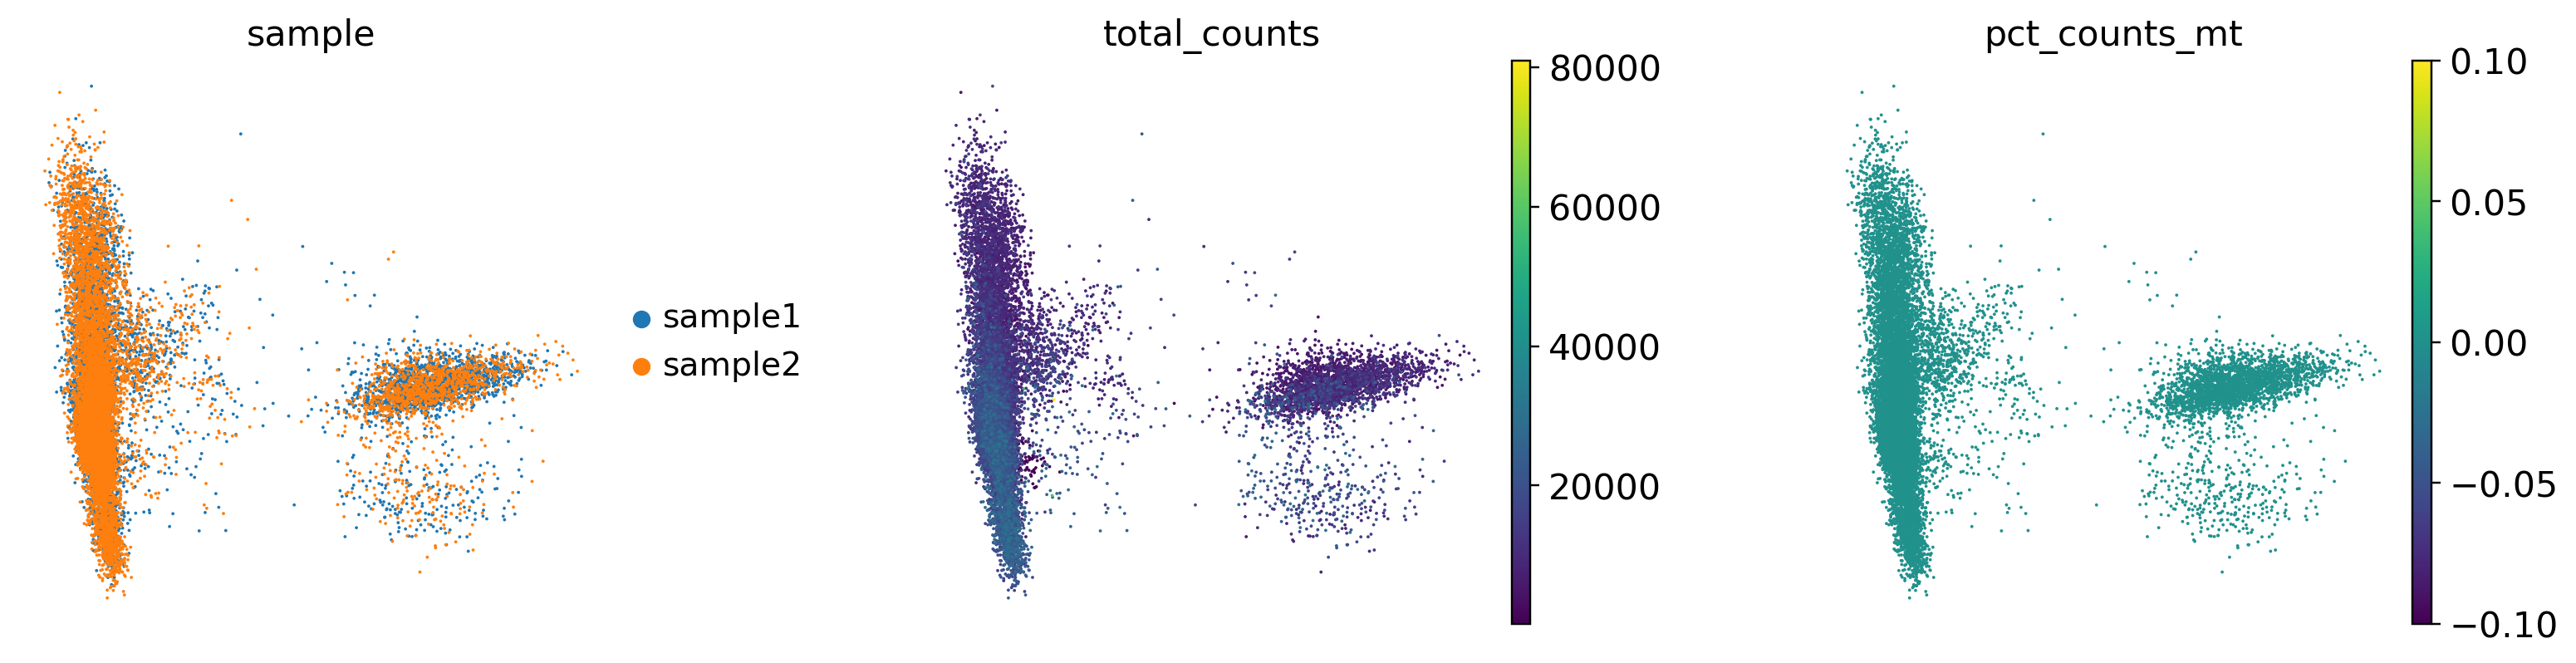

In [16]:
sc.pl.pca(
    adata,
    color=["sample", "total_counts", "pct_counts_mt"],
    use_raw=False,
    ncols=3,
    wspace=0.4,
    show=False,
)
plt.show()

=== [GRCm39_Cd3d] Gene QC / HVG Info ===


,highly_variable,dispersions_norm
GRCm39_Cd3d,True,4.23286


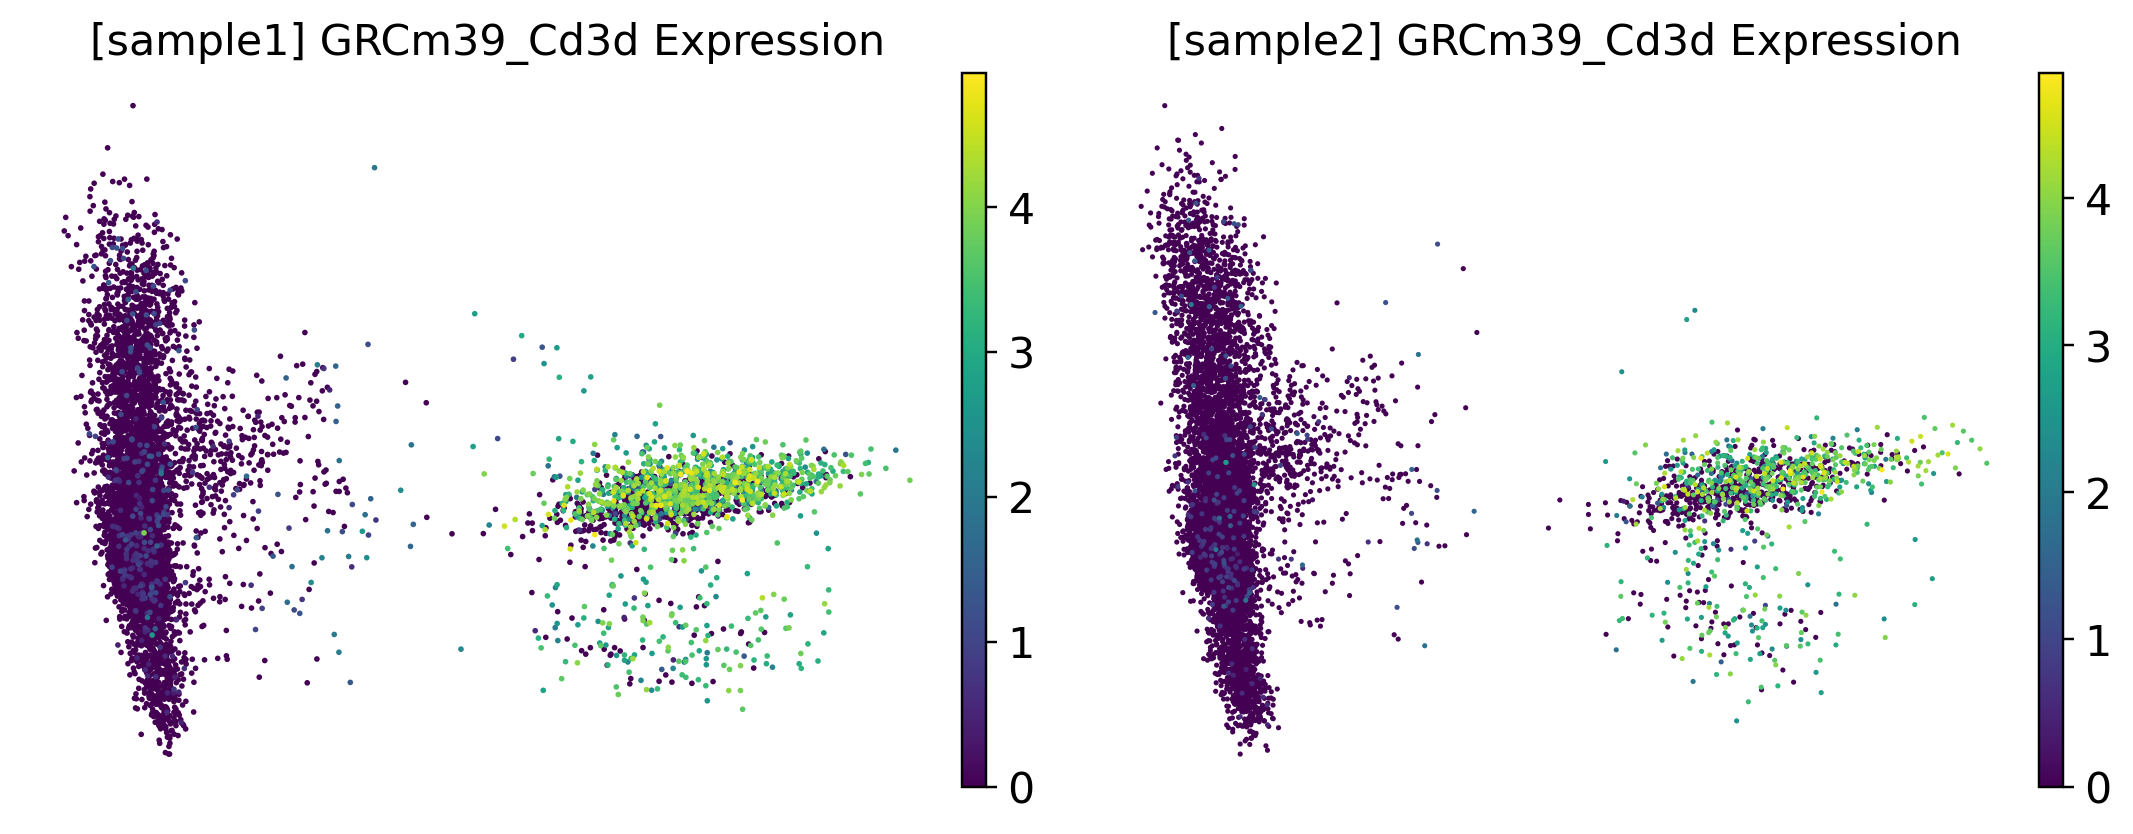

In [19]:
# 1. 비교하고 싶은 유전자 설정
# (만약 유전자 이름 앞에 GRCh38_ 또는 GRCm39_ 가 붙어있다면 "GRCm39_Cd3d" 형태로 변경해 주세요)
target_gene = "GRCm39_Cd3d"  # 예시: CD3D (마우스 형태: Cd3d)

# 2. 유전자가 adata.var_names에 존재하는지 미리 확인
if target_gene not in adata.var_names:
    # 대소문자나 Prefix로 인해 못 찾는 경우 찾아서 알려주는 코드
    matched = [g for g in adata.var_names if target_gene.lower() in g.lower()]
    print(f"'{target_gene}' 유전자를 찾을 수 없습니다. 유사한 유전자 이름 목록: {matched}")
else:
    # 3. 유전자 정보 표 출력
    print(f"=== [{target_gene}] Gene QC / HVG Info ===")
    display(adata.var.loc[[target_gene], ["highly_variable", "dispersions_norm"]])

    # 4. 각 데이터셋(샘플)별로 PCA 상에서 해당 유전자 표현량 비교 시각화
    samples = adata.obs["sample"].unique()
    fig, axes = plt.subplots(1, len(samples), figsize=(5 * len(samples), 4))

    for idx, sample_id in enumerate(samples):
        ax = axes[idx] if len(samples) > 1 else axes
        sub_adata = adata[adata.obs["sample"] == sample_id]

        # 샘플별 PCA 산점도 및 유전자 표현량 시각화
        sc.pl.pca(
            sub_adata,
            color=target_gene,
            use_raw=False,
            cmap="viridis",
            ax=ax,
            show=False,
            title=f"[{sample_id}] {target_gene} Expression"
        )

    plt.tight_layout()
    plt.show()

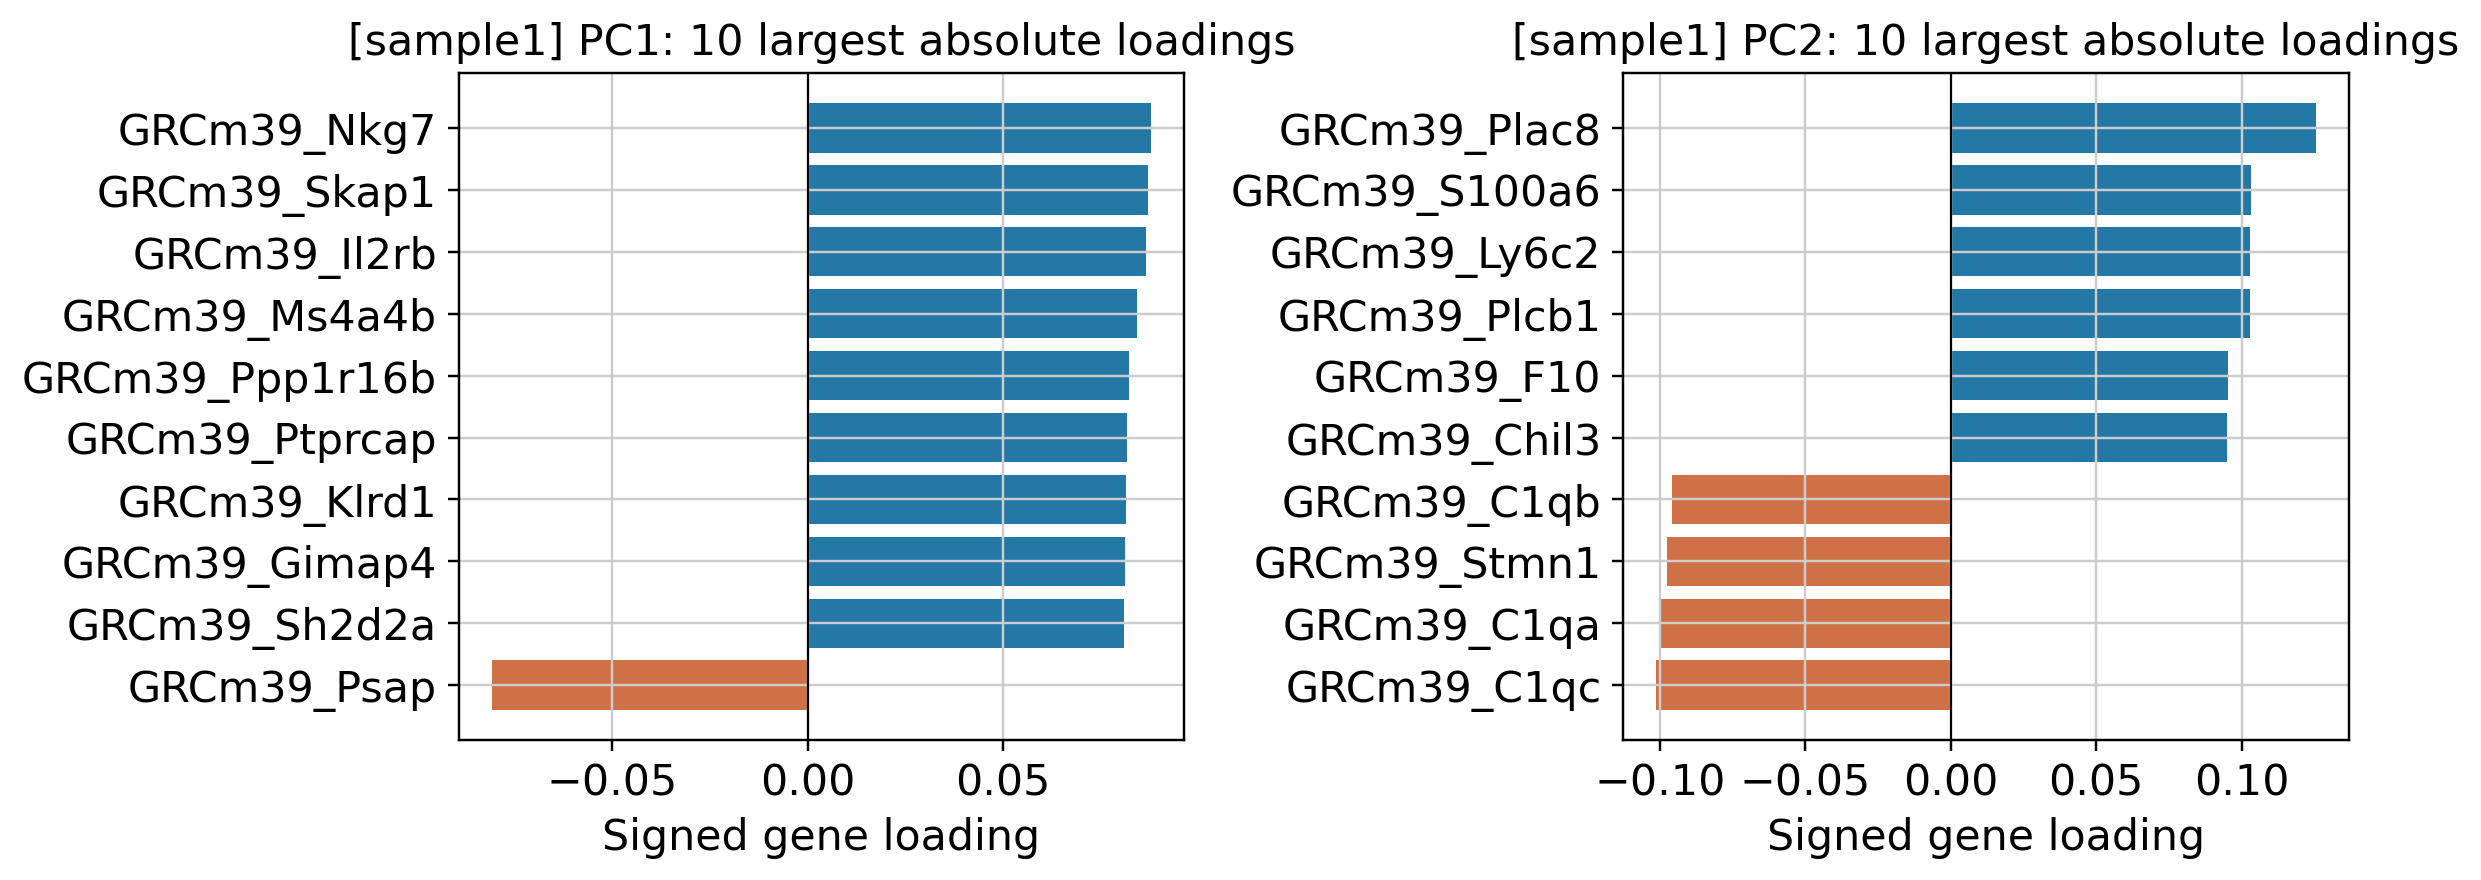

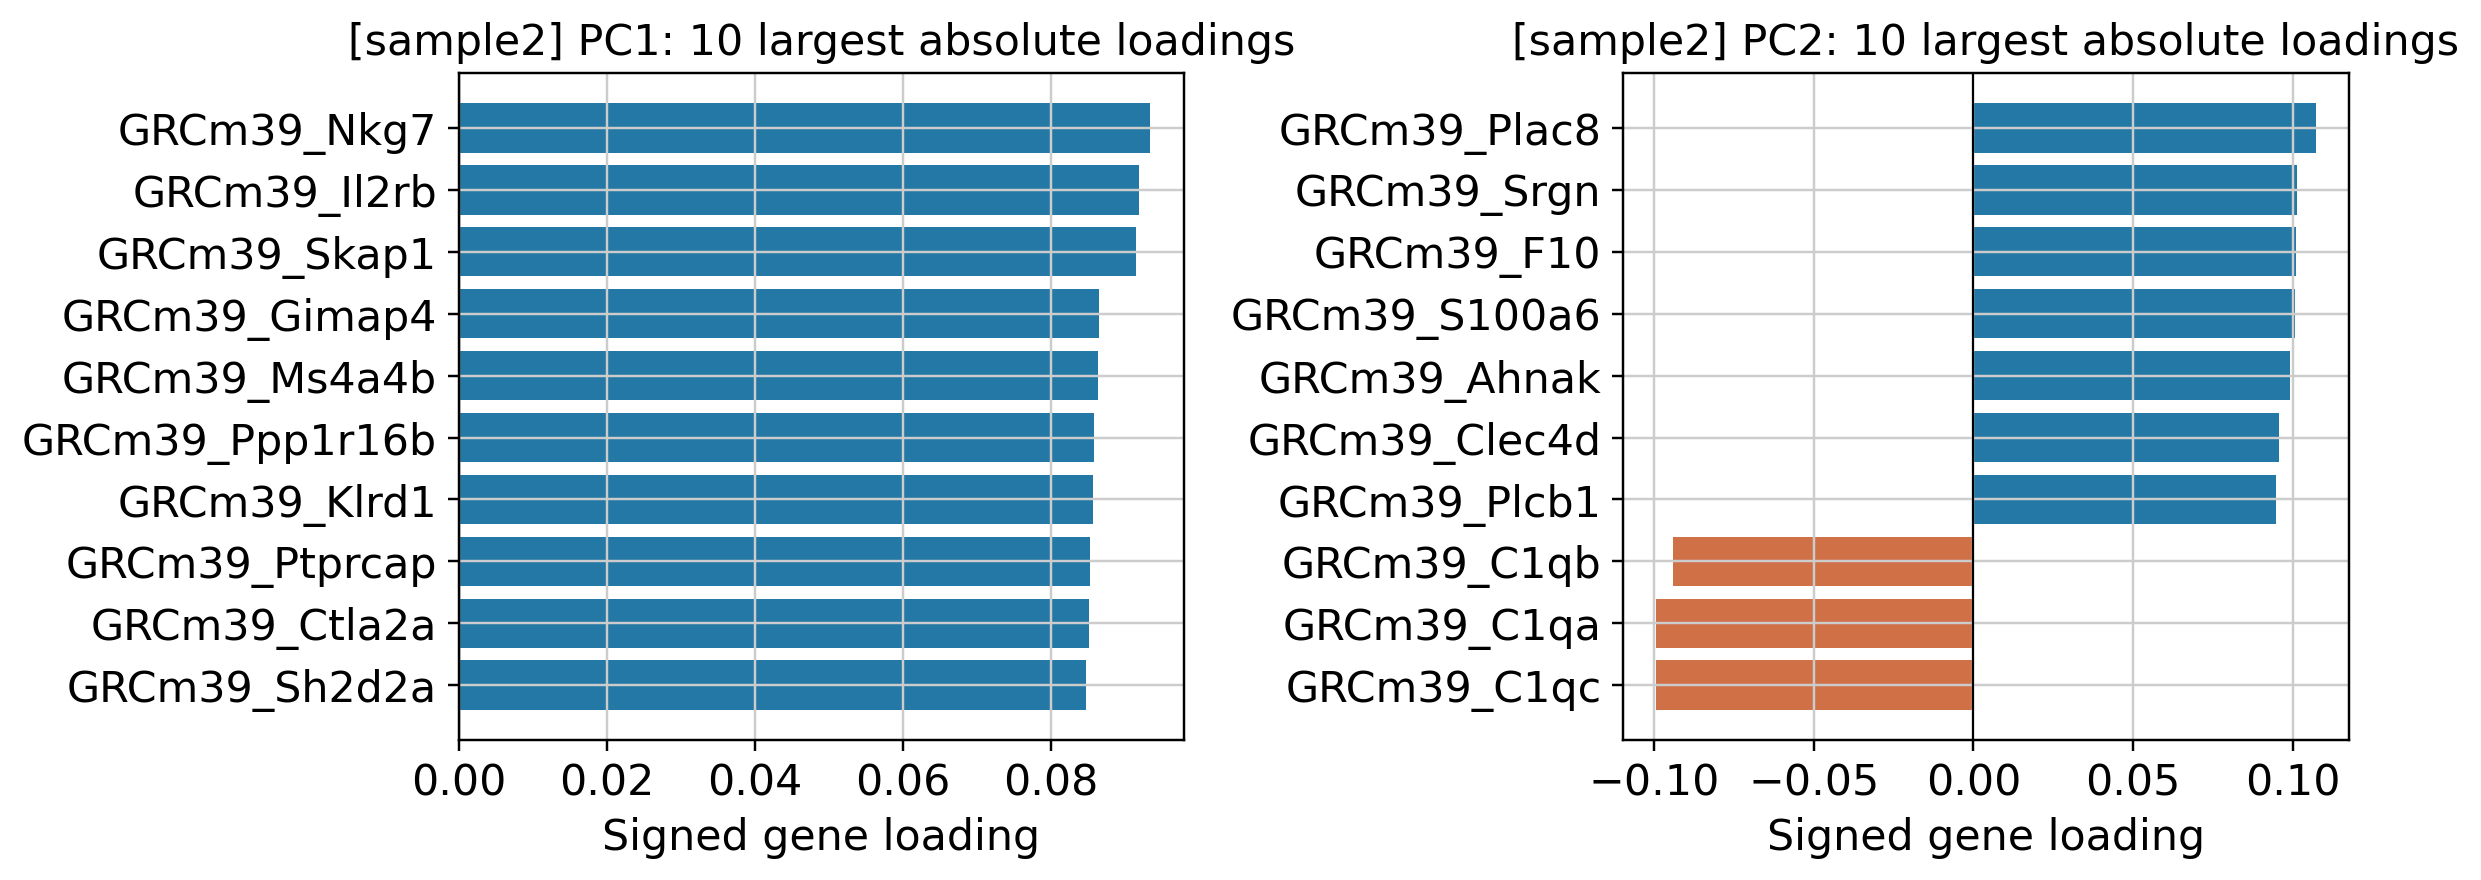

In [20]:
samples = adata.obs["sample"].unique()

# Aggimalis iti tunggal sample tapno maibinglay dagiti bar chart
for sample_id in samples:
    # 1. Panagpili iti Sample ken panagpreparar iti data
    sub_adata = adata[adata.obs["sample"] == sample_id].copy()
    pca_data = sub_adata[:, sub_adata.var["highly_variable"]].copy()

    if sparse.issparse(pca_data.X):
        pca_data.X = pca_data.X.toarray()

    sc.pp.scale(pca_data, zero_center=True, max_value=10)
    sc.pp.pca(pca_data, n_comps=30, svd_solver="arpack", random_state=0)

    # 2. Panagkarkulo iti Gene Loadings
    loadings = pd.DataFrame(
        pca_data.varm["PCs"],
        index=pca_data.var_names,
        columns=[f"PC{i + 1}" for i in range(pca_data.varm["PCs"].shape[1])],
    )

    # 3. Plotting para iti sangasaka a sample
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, pc in zip(axes, ["PC1", "PC2"]):
        selected = loadings[pc].abs().nlargest(10).index
        values = loadings.loc[selected, pc].sort_values()

        ax.barh(
            values.index,
            values.values,
            color=np.where(values.values >= 0, "#2378a5", "#cf7047"),
        )
        ax.axvline(0, color="black", linewidth=0.7)
        ax.set(
            title=f"[{sample_id}] {pc}: 10 largest absolute loadings",
            xlabel="Signed gene loading",
        )

    fig.tight_layout()
    plt.show()

GRCm39_Cd3d | Selected as an HVG: True


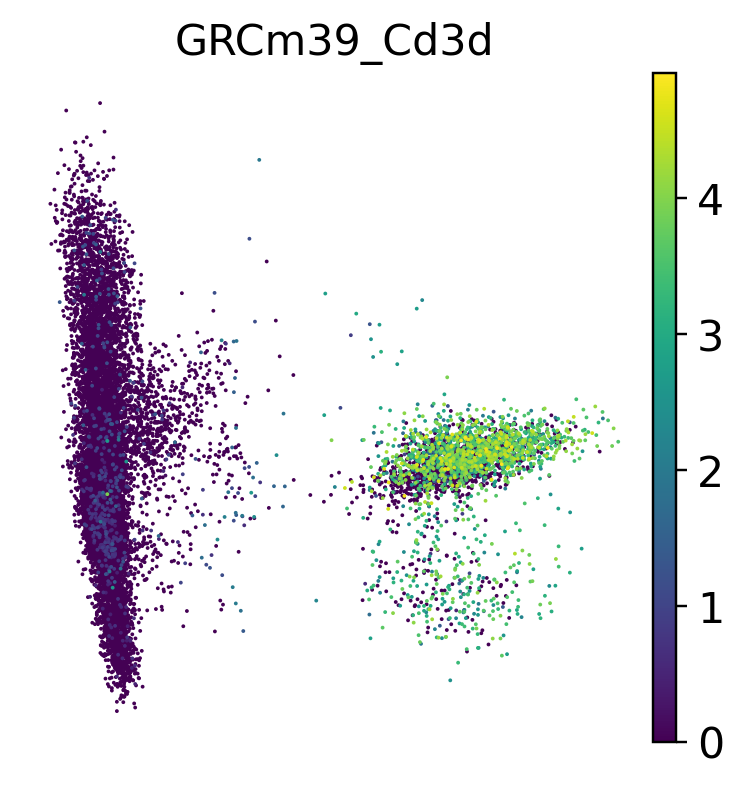

In [22]:
GENE = "GRCm39_Cd3d"

if GENE not in adata.var_names:
    print("Gene not found. Copy an exact gene symbol from the displayed tables.")
else:
    print(GENE, "| Selected as an HVG:", bool(adata.var.loc[GENE, "highly_variable"]))
    sc.pl.pca(adata, color=GENE, use_raw=False, cmap="viridis", show=False)
    plt.show()